# Model Calibration: Do Predicted Probabilities Match Observed Rates?

**Dataset:** `telco_churn` | **Level:** advanced

Compare raw, sigmoid and isotonic calibrated probabilities with the Brier score and reliability curves.

Sections: 1 Problem, 2 Method, 3 Setup and data, 4 Experiment, 5 Results, 6 Interpretation, 7 Limitations, 8 Exercises, 9 References.

## 1. Problem

A churn score is used to estimate how many customers will leave and to apply a cost threshold. That needs probabilities that match observed frequencies. Tree ensembles are often miscalibrated.

## 2. Method

Fit a random forest and a histogram gradient boosting model. Calibrate each with sigmoid and isotonic regression using 5-fold cross fitting on the training rows. Compare Brier score (mean squared error of the probability, lower is better) and expected calibration error (ECE) with 10 equal count bins on the test rows.

## 3. Setup and data

Telco customer churn (7043 rows, 21 columns, about 26.5 percent churn). Source and checksum are documented in `datasets/catalog/supervised.json` and `01_supervised_learning/` notebooks.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
NB_ID = "model_calibration"
SEED = 42
set_seed(SEED); viz.apply_style(); print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
b = load_dataset("telco_churn"); X, y = b.X, b.y
Xtr, Xva, Xte, ytr, yva, yte = split_three_way(X, y, task="classification", seed=SEED)
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, brier_score_loss
print(len(Xtr), len(Xva), len(Xte), "| churn share", round(float(y.mean()), 3))

4225 1409 1409 | churn share 0.265


## 4. Experiment

Fit and calibrate.

In [3]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from ml_lab.preprocessing import build_preprocessor
base = {"forest": RandomForestClassifier(300, min_samples_leaf=3, n_jobs=2, random_state=SEED), "hist_gb": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)}
models = {}
for n, m in base.items():
    pre = build_preprocessor(Xtr, scale=False)
    models[(n, "raw")] = Pipeline([("prep", pre), ("model", clone(m))]).fit(Xtr, ytr)
    for method in ["sigmoid", "isotonic"]:
        models[(n, method)] = Pipeline([("prep", build_preprocessor(Xtr, scale=False)), ("model", CalibratedClassifierCV(clone(m), method=method, cv=5))]).fit(Xtr, ytr)
def ece(y_true, p, bins=10):
    q = np.quantile(p, np.linspace(0, 1, bins + 1)); q[0], q[-1] = -1, 2
    idx = np.digitize(p, q[1:-1]); return float(sum(abs(y_true[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any()))
print(len(models), "models")

6 models


## 5. Results

Test rows.

,model,calibration,Brier,ECE,ROC_AUC
0,forest,raw,0.1395,0.0233,0.8355
1,forest,sigmoid,0.1396,0.0391,0.8383
2,forest,isotonic,0.1385,0.0159,0.8383
3,hist_gb,raw,0.1359,0.0134,0.8431
4,hist_gb,sigmoid,0.1350,0.0218,0.8455
5,hist_gb,isotonic,0.1361,0.0295,0.8445


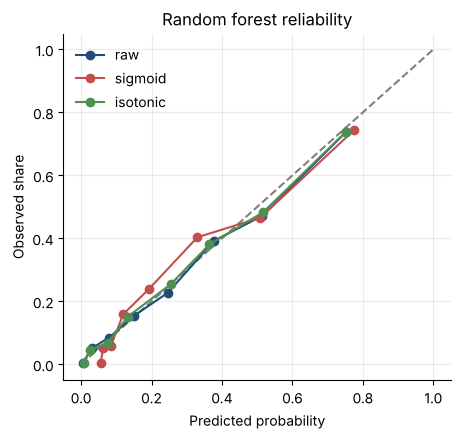

saved: experiments/results/model_calibration.json


In [4]:
rows = []
for (n, method), m in models.items():
    p = m.predict_proba(Xte)[:, 1]
    rows.append({"model": n, "calibration": method, "Brier": brier_score_loss(yte, p), "ECE": ece(yte.values, p), "ROC_AUC": roc_auc_score(yte, p)})
tab = pd.DataFrame(rows); display(tab.round(4))
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.plot([0, 1], [0, 1], "--", color="gray")
for (n, method), m in models.items():
    if n == "forest":
        f, mp = calibration_curve(yte, m.predict_proba(Xte)[:, 1], n_bins=8, strategy="quantile"); ax.plot(mp, f, marker="o", label=method)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed share"); ax.legend(); ax.set_title("Random forest reliability"); save_figure(fig, NB_ID, "reliability"); plt.show()
METRICS = {f"{r.model}_{r.calibration}_{k}": float(getattr(r, k)) for r in tab.itertuples() for k in ["Brier", "ECE", "ROC_AUC"]}
CONFIG = {"cv": 5, "bins": 10, "methods": ["raw", "sigmoid", "isotonic"]}; EXTRA = {"table": tab.round(4).to_dict("records")}; ALGORITHM = "CalibratedClassifierCV"

record = ExperimentRecord(notebook=NB_ID, family="advanced", algorithm=ALGORITHM, dataset="telco_churn", task="classification", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())

## 6. Interpretation

Compare Brier and ECE within each model. Calibration should leave ROC-AUC almost unchanged because it is a monotone transformation (isotonic can create ties). A lower Brier with similar ROC-AUC indicates better probabilities, not a better ranking.

## 7. Limitations

Single split. ECE with 10 bins on about 1400 test rows is noisy. Isotonic regression can overfit with few rows.

## 8. Exercises

1. Bootstrap the test rows to put an interval on ECE.
2. Calibrate on a separate validation set instead of cross fitting.
3. Check calibration inside each contract type.

## 9. References

Calibration methods are implemented in scikit-learn (`CalibratedClassifierCV`). The usual paper references (Platt 1999, Zadrozny and Elkan 2002, Guo et al. 2017) are **not verified in the build environment**; check them before citing.